In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
print(os.listdir("data"))

['dirty_cafe_sales.csv']


In [3]:
df_raw = pd.read_csv("data/dirty_cafe_sales.csv")
df = df_raw.copy()
print(df_raw.shape)
df_raw.head(10)

(10000, 8)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 1.1 MB


In [5]:
quality = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "nulls": df_raw.isna().sum(),
    "null %": (df_raw.isna().mean() * 100).round(1),
    "unique values": df_raw.nunique()
})
quality

,dtype,nulls,null %,unique values
Transaction ID,str,0,0.0,10000
Item,str,333,3.3,10
Quantity,str,138,1.4,7
Price Per Unit,str,179,1.8,8
Total Spent,str,173,1.7,19
Payment Method,str,2579,25.8,5
Location,str,3265,32.6,4
Transaction Date,str,159,1.6,367


In [6]:
print("Fully duplicated rows:", df_raw.duplicated().sum())
id_cols = [c for c in df_raw.columns if "id" in c.lower()]
for c in id_cols:
    print(c, "repeated values:", df_raw[c].duplicated().sum())

Fully duplicated rows: 0
Transaction ID repeated values: 0


In [7]:
placeholders = {"error", "unknown", "n/a", "na", "nan", "null", "none", "?", "-", "--", "", "missing", "undefined"}

text_cols = [c for c in df_raw.columns
             if not pd.api.types.is_numeric_dtype(df_raw[c]) and not pd.api.types.is_datetime64_any_dtype(df_raw[c])]

def placeholder_counts(d):
    out = {}
    for c in text_cols:
        s = d[c].dropna().astype(str).str.strip().str.lower()
        n = int(s.isin(placeholders).sum())
        if n:
            out[c] = n
    return pd.Series(out, name="placeholder values", dtype="int64")

placeholder_counts(df_raw)

Item                636
Quantity            341
Price Per Unit      354
Total Spent         329
Payment Method      599
Location            696
Transaction Date    301
Name: placeholder values, dtype: int64

In [8]:
for c in text_cols:
    s = df_raw[c].dropna().astype(str)
    raw_unique = s.nunique()
    norm_unique = s.str.strip().str.lower().nunique()
    print(f"{c}: {raw_unique} unique values, {norm_unique} after trimming and lower-casing")
    if raw_unique <= 15:
        print(s.value_counts().to_string())
    print()

Transaction ID: 10000 unique values, 10000 after trimming and lower-casing

Item: 10 unique values, 10 after trimming and lower-casing
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
ERROR        292

Quantity: 7 unique values, 7 after trimming and lower-casing
Quantity
5          2013
2          1974
4          1863
3          1849
1          1822
UNKNOWN     171
ERROR       170

Price Per Unit: 8 unique values, 8 after trimming and lower-casing
Price Per Unit
3.0        2429
4.0        2331
2.0        1227
5.0        1204
1.0        1143
1.5        1133
ERROR       190
UNKNOWN     164

Total Spent: 19 unique values, 19 after trimming and lower-casing

Payment Method: 5 unique values, 5 after trimming and lower-casing
Payment Method
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293

Location: 4 unique values, 4 a

In [9]:
for c in text_cols:
    s = df_raw[c].dropna().astype(str).str.strip()
    as_num = pd.to_numeric(s, errors="coerce").notna().mean()
    as_date = pd.to_datetime(s, errors="coerce", format="mixed").notna().mean()
    print(f"{c}: {as_num * 100:.0f}% parse as numbers, {as_date * 100:.0f}% parse as dates")

Transaction ID: 0% parse as numbers, 0% parse as dates
Item: 0% parse as numbers, 0% parse as dates
Quantity: 97% parse as numbers, 0% parse as dates
Price Per Unit: 96% parse as numbers, 0% parse as dates
Total Spent: 97% parse as numbers, 0% parse as dates
Payment Method: 0% parse as numbers, 0% parse as dates
Location: 0% parse as numbers, 0% parse as dates
Transaction Date: 0% parse as numbers, 97% parse as dates


In [10]:
num_cols = df_raw.select_dtypes(include="number").columns.tolist()
print(num_cols)
df_raw[num_cols].describe().round(2) if num_cols else print("No numeric columns detected")

[]
No numeric columns detected


In [11]:
before = {
    "Rows": len(df_raw),
    "Columns": df_raw.shape[1],
    "Null cells (as loaded)": int(df_raw.isna().sum().sum()),
    "Placeholder values (hidden nulls)": int(placeholder_counts(df_raw).sum()),
    "Duplicate rows": int(df_raw.duplicated().sum()),
}
before

{'Rows': 10000,
 'Columns': 8,
 'Null cells (as loaded)': 6826,
 'Placeholder values (hidden nulls)': 3256,
 'Duplicate rows': 0}

In [12]:
df = df_raw.copy()
for c in df.columns:
    s = df[c].astype("string").str.strip()
    df[c] = s.mask(s.str.lower().isin(placeholders))

after_placeholders = df.isna().sum()
pd.DataFrame({
    "nulls as loaded": df_raw.isna().sum(),
    "placeholders": placeholder_counts(df_raw).reindex(df.columns).fillna(0).astype(int),
    "nulls now": after_placeholders,
    "missing %": (after_placeholders / len(df) * 100).round(1)
})

,nulls as loaded,placeholders,nulls now,missing %
Transaction ID,0,0,0,0.0
Item,333,636,969,9.7
Quantity,138,341,479,4.8
Price Per Unit,179,354,533,5.3
Total Spent,173,329,502,5.0
Payment Method,2579,599,3178,31.8
Location,3265,696,3961,39.6
Transaction Date,159,301,460,4.6


In [13]:
print(after_placeholders.sum(), before["Null cells (as loaded)"] + before["Placeholder values (hidden nulls)"])

10082 10082


In [14]:
raw_dates = df_raw["Transaction Date"].dropna().astype(str).str.strip()
bad = raw_dates[~raw_dates.str.match(r"^\d{4}-\d{2}-\d{2}$") & ~raw_dates.str.lower().isin(placeholders)]
print("Dates not in YYYY-MM-DD format:", len(bad))
print("IDs matching TXN_ + 7 digits:", df["Transaction ID"].str.match(r"^TXN_\d{7}$").mean())

Dates not in YYYY-MM-DD format: 0
IDs matching TXN_ + 7 digits: 1.0


In [15]:
for c in ["Quantity", "Price Per Unit", "Total Spent"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["Quantity"] = df["Quantity"].astype("Int64")
df["Transaction Date"] = pd.to_datetime(df["Transaction Date"], format="%Y-%m-%d", errors="coerce")

print(df.dtypes)
print("No new nulls created:", (df.isna().sum() == after_placeholders).all())

Transaction ID              string
Item                        string
Quantity                     Int64
Price Per Unit             Float64
Total Spent                Float64
Payment Method              string
Location                    string
Transaction Date    datetime64[us]
dtype: object
No new nulls created: True


In [16]:
pi = df.dropna(subset=["Item", "Price Per Unit"])
print(pi.groupby("Item")["Price Per Unit"].agg(["nunique", "min", "max", "count"]))
print()
print(pi.groupby("Price Per Unit")["Item"].unique())

          nunique  min  max  count
Item                              
Cake            1  3.0  3.0   1085
Coffee          1  2.0  2.0   1108
Cookie          1  1.0  1.0   1026
Juice           1  3.0  3.0   1110
Salad           1  5.0  5.0   1082
Sandwich        1  4.0  4.0   1082
Smoothie        1  4.0  4.0   1036
Tea             1  1.5  1.5   1023

Price Per Unit
1.0                [Cookie]
1.5                   [Tea]
2.0                [Coffee]
3.0           [Cake, Juice]
4.0    [Smoothie, Sandwich]
5.0                 [Salad]
Name: Item, dtype: object


In [17]:
full = df.dropna(subset=["Quantity", "Price Per Unit", "Total Spent"])
ok = np.isclose(full["Total Spent"].astype(float), full["Quantity"].astype(float) * full["Price Per Unit"])
print("Rows with all three values:", len(full))
print("Total = Quantity x Price in", round(ok.mean() * 100, 2), "% of them")

Rows with all three values: 8544
Total = Quantity x Price in 100.0 % of them


In [18]:
missing_numeric = df[["Quantity", "Price Per Unit", "Total Spent"]].isna().sum(axis=1)
print(missing_numeric.value_counts().sort_index().rename("rows"))

0    8544
1    1398
2      58
Name: rows, dtype: int64


In [19]:
d = df["Transaction Date"].dropna()
print("Rows in date order:", d.is_monotonic_increasing)
print(d.min().date(), d.max().date(), d.nunique())

Rows in date order: False
2023-01-01 2023-12-31 365


In [20]:
print("Rows with at least one missing value:", int(df.isna().any(axis=1).sum()), "of", len(df))
print("Rows with no missing values:", int((~df.isna().any(axis=1)).sum()))

Rows with at least one missing value: 6911 of 10000
Rows with no missing values: 3089


## 1. Data Quality Report (before cleaning)

**Dataset:** Cafe Sales - Dirty Data for Cleaning Training (Kaggle), 10,000 transactions, 8 columns. Every column loads as text.

### Missing data
Two kinds of missing values exist. Standard nulls are counted by pandas. Placeholder strings (`ERROR`, `UNKNOWN`) are not, so they hide as ordinary text.

| Column | Nulls | Placeholders | Total missing | % missing |
|---|---|---|---|---|
| Transaction ID | 0 | 0 | 0 | 0.0% |
| Item | 333 | 636 | 969 | 9.7% |
| Quantity | 138 | 341 | 479 | 4.8% |
| Price Per Unit | 179 | 354 | 533 | 5.3% |
| Total Spent | 173 | 329 | 502 | 5.0% |
| Payment Method | 2,579 | 599 | 3,178 | **31.8%** |
| Location | 3,265 | 696 | 3,961 | **39.6%** |
| Transaction Date | 159 | 301 | 460 | 4.6% |
| **Total** | **6,826** | **3,256** | **10,082** | 12.6% of all cells |

- **pandas reports only 6,826 nulls, but 10,082 cells are effectively missing.** Placeholders add 3,256 hidden missing values (48% more).
- **Payment Method and Location are the worst columns**, with about a third and two fifths of their values missing.

### Duplicates
- **0 fully duplicated rows** and 0 repeated Transaction IDs (all 10,000 IDs are unique), so no rows need removing.

### Data type problems
| Column | Loaded as | Should be | Problem |
|---|---|---|---|
| Transaction ID | text | string | correct |
| Item | text | category | correct (text) |
| Quantity | text | integer | numbers stored as text |
| Price Per Unit | text | float | numbers stored as text |
| Total Spent | text | float | numbers stored as text |
| Payment Method | text | category | correct (text) |
| Location | text | category | correct (text) |
| Transaction Date | text | datetime | dates stored as text |

Only **4 of 8** columns have the correct type before cleaning.

### Formatting and value checks
- No case or spacing inconsistencies: every text column has the same number of unique values before and after trimming and lower-casing.
- Valid values found: 8 items (Juice, Coffee, Salad, Cake, Sandwich, Smoothie, Cookie, Tea), quantities 1 to 5, six prices (1.0, 1.5, 2.0, 3.0, 4.0, 5.0), three payment methods (Digital Wallet, Credit Card, Cash) and two locations (Takeaway, In-store). Every other value is a placeholder.
- Total Spent has 17 valid values, which fits quantity times a menu price.
- Numeric ranges and outliers can only be checked after the type conversion (the next section).

In [21]:
known = df.dropna(subset=["Item", "Price Per Unit"])
price_by_item = known.groupby("Item")["Price Per Unit"].first().astype(float).to_dict()
n_items = known.groupby("Price Per Unit")["Item"].nunique()
unique_price_map = known[known["Price Per Unit"].isin(n_items[n_items == 1].index)].groupby("Price Per Unit")["Item"].first()
item_by_unique_price = {float(k): v for k, v in unique_price_map.items()}
print(price_by_item)
print(item_by_unique_price)

{'Cake': 3.0, 'Coffee': 2.0, 'Cookie': 1.0, 'Juice': 3.0, 'Salad': 5.0, 'Sandwich': 4.0, 'Smoothie': 4.0, 'Tea': 1.5}
{1.0: 'Cookie', 1.5: 'Tea', 2.0: 'Coffee', 5.0: 'Salad'}


In [22]:
df_clean = df.copy()
missing_before = df_clean.isna().sum()

for _ in range(3):
    df_clean["Price Per Unit"] = df_clean["Price Per Unit"].fillna(df_clean["Item"].map(price_by_item).astype("Float64"))
    df_clean["Price Per Unit"] = df_clean["Price Per Unit"].fillna((df_clean["Total Spent"] / df_clean["Quantity"]).round(2))
    qty = (df_clean["Total Spent"] / df_clean["Price Per Unit"]).round().astype("Int64")
    df_clean["Quantity"] = df_clean["Quantity"].fillna(qty)
    df_clean["Total Spent"] = df_clean["Total Spent"].fillna(df_clean["Quantity"].astype("Float64") * df_clean["Price Per Unit"])
    item = df_clean["Price Per Unit"].astype(float).map(item_by_unique_price).astype("string")
    df_clean["Item"] = df_clean["Item"].fillna(item)

still = df_clean.isna().sum()
pd.DataFrame({
    "missing before": missing_before,
    "recovered": missing_before - still,
    "still missing": still,
    "still missing %": (still / len(df_clean) * 100).round(1)
})

,missing before,recovered,still missing,still missing %
Transaction ID,0,0,0,0.0
Item,969,489,480,4.8
Quantity,479,456,23,0.2
Price Per Unit,533,527,6,0.1
Total Spent,502,479,23,0.2
Payment Method,3178,0,3178,31.8
Location,3961,0,3961,39.6
Transaction Date,460,0,460,4.6


In [23]:
chk = df_clean.dropna(subset=["Quantity", "Price Per Unit", "Total Spent"])
print("Total = Quantity x Price:", np.isclose(chk["Total Spent"].astype(float), chk["Quantity"].astype(float) * chk["Price Per Unit"].astype(float)).mean())
print("Quantity range:", chk["Quantity"].min(), "to", chk["Quantity"].max())
print("Prices:", sorted(chk["Price Per Unit"].astype(float).unique()))
ik = chk.dropna(subset=["Item"])
print("Item and price mismatches:", int((ik["Item"].map(price_by_item).astype(float) != ik["Price Per Unit"].astype(float)).sum()))

Total = Quantity x Price: 1.0
Quantity range: 1 to 5
Prices: [np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
Item and price mismatches: 0


In [24]:
unfixable = df_clean[["Quantity", "Price Per Unit", "Total Spent"]].isna().any(axis=1)
print("Rows still missing a numeric field:", int(unfixable.sum()), f"({unfixable.mean() * 100:.2f}% of rows)")
df_clean[unfixable].head(8)

Rows still missing a numeric field: 26 (0.26% of rows)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
236,TXN_8562645,Salad,<NA>,5.0,<NA>,<NA>,In-store,2023-05-18
278,TXN_3229409,Juice,<NA>,3.0,<NA>,Cash,Takeaway,2023-04-15
641,TXN_2962976,Juice,<NA>,3.0,<NA>,<NA>,<NA>,2023-03-17
738,TXN_8696094,Sandwich,<NA>,4.0,<NA>,<NA>,Takeaway,2023-05-14
1761,TXN_3611851,<NA>,4,<NA>,<NA>,Credit Card,<NA>,2023-02-09
2289,TXN_7524977,<NA>,4,<NA>,<NA>,<NA>,<NA>,2023-12-09
2796,TXN_9188692,Cake,<NA>,3.0,<NA>,Credit Card,<NA>,2023-12-01
3203,TXN_4565754,Smoothie,<NA>,4.0,<NA>,Digital Wallet,Takeaway,2023-10-06


In [25]:
rows_before = len(df_clean)
df_clean = df_clean[~unfixable].copy()
rows_deleted = rows_before - len(df_clean)

for c in ["Item", "Payment Method", "Location"]:
    n = int(df_clean[c].isna().sum())
    df_clean[c] = df_clean[c].fillna("Unknown")
    print(f"{c}: {n} missing values labelled 'Unknown'")

print("Rows deleted:", rows_deleted)
print("Rows now:", len(df_clean))
print("Missing values left:")
print(df_clean.isna().sum())

Item: 474 missing values labelled 'Unknown'
Payment Method: 3168 missing values labelled 'Unknown'
Location: 3952 missing values labelled 'Unknown'
Rows deleted: 26
Rows now: 9974
Missing values left:
Transaction ID        0
Item                  0
Quantity              0
Price Per Unit        0
Total Spent           0
Payment Method        0
Location              0
Transaction Date    460
dtype: int64


In [26]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate Transaction IDs:", df_clean["Transaction ID"].duplicated().sum())
dups_removed = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Rows after duplicate check:", len(df_clean))

Duplicate rows: 0
Duplicate Transaction IDs: 0
Rows after duplicate check: 9974


## 2. Missing Data Handling

Two kinds of missing values exist: real nulls and placeholder text (`ERROR`, `UNKNOWN`). All placeholders were first converted to proper missing values, which raised the null count from 6,826 to **10,082** (12.6% of all cells). Incomplete rows are common: **6,911 of 10,000 rows (69.1%) have at least one gap**, so deleting every incomplete row would discard most of the data. The strategy therefore differs by column.

### Facts verified in the data before choosing a strategy
- **Total Spent = Quantity x Price Per Unit** in 100% of the 8,544 rows that have all three values.
- **Each item has exactly one price**: Cookie 1.0, Tea 1.5, Coffee 2.0, Cake 3.0, Juice 3.0, Smoothie 4.0, Sandwich 4.0, Salad 5.0.
- 1,398 rows are missing exactly one of the three numeric fields and 58 are missing two.
- Rows are **not** in date order, so neighbouring rows say nothing about a missing date.

### Strategy per column

| Column | Missing | Strategy | Why this and not another |
|---|---|---|---|
| Quantity | 479 (4.8%) | **Recompute** as Total / Price where both are known; unresolvable rows deleted | Mean or median imputation would be wrong: quantity is spread almost evenly across 1 to 5 (1,822 to 2,013 rows each), so an average would be an invented value. The formula is exact. |
| Price Per Unit | 533 (5.3%) | **Recover** from the item's fixed menu price, or as Total / Quantity | Prices are fixed per item, so the true value is known, not estimated. |
| Total Spent | 502 (5.0%) | **Recompute** as Quantity x Price | The relationship holds in 100% of complete rows, so this is exact. |
| Item | 969 (9.7%) | **Recover from price** where the price identifies one item (1.0, 1.5, 2.0, 5.0); label the rest **"Unknown"** | A price of 3.0 fits both Cake and Juice and 4.0 fits both Smoothie and Sandwich, so those rows cannot be resolved. Mode imputation would assign every one of them to the overall most common item (Juice) and distort item sales. |
| Payment Method | 3,178 (31.8%) | Label **"Unknown"** | Nothing in the data predicts the payment method. The three methods are almost equally common (2,291 / 2,273 / 2,258), so mode imputation would pile about 3,000 invented values onto one method. Deleting the rows would lose about a third of the data. |
| Location | 3,961 (39.6%) | Label **"Unknown"** | Takeaway (3,022) and In-store (3,017) are equally common, and about 40% missing is too much to delete or to guess. |
| Transaction Date | 460 (4.6%) | **Keep as missing (NaT)** | Forward fill is invalid because the rows are not in date order, and the Transaction ID carries no date information. Invented dates would corrupt any time analysis. The 95.4% of rows with a date stay fully usable. |
| Transaction ID | 0 | none needed | |

### Result of the cleaning

| Column | Missing before | Recovered exactly | Still missing | Final treatment |
|---|---|---|---|---|
| Item | 969 | 489 | 480 | 474 labelled "Unknown" (6 were in deleted rows) |
| Quantity | 479 | 456 | 23 | rows deleted |
| Price Per Unit | 533 | 527 | 6 | rows deleted |
| Total Spent | 502 | 479 | 23 | rows deleted |
| Payment Method | 3,178 | 0 | 3,178 | 3,168 labelled "Unknown" |
| Location | 3,961 | 0 | 3,961 | 3,952 labelled "Unknown" |
| Transaction Date | 460 | 0 | 460 | 460 kept as missing |

- **1,462 of 1,514 missing numeric values (96.6%) were recovered exactly**, not estimated. Every row missing a single numeric field was fixed (1,398 rows), as were 32 of the 58 rows missing two.
- **Rows deleted: 26 (0.26% of the data).** Each was missing two numeric fields in a combination no rule could resolve (for example both Quantity and Total Spent), and keeping them would have required inventing numbers. This is the only point where rows were removed. **9,974 rows remain.**
- **Labelled "Unknown":** Item 474, Payment Method 3,168, Location 3,952. This replaces the mixture of blank values and `ERROR` / `UNKNOWN` strings with one consistent label per column.
- **Dates left missing:** 460 rows (4.6%).
- **Validation after cleaning:** Total = Quantity x Price holds in 100.0% of rows, quantities range from 1 to 5, every price is on the menu (1.0, 1.5, 2.0, 3.0, 4.0, 5.0), and 0 item and price mismatches were found.

## 3. Duplicate Removal
- Fully duplicated rows found: **0**. Repeated Transaction IDs: **0**, since all IDs are unique.
- **Duplicates removed: 0.** No rows needed dropping. The check was repeated after the missing-value step, because recovery can create identical rows, and it again found none. Rows remaining: **9,974**.
- Recording this result matters: a dataset described as "dirty" does not always contain every kind of dirt, and removing rows that are not true duplicates would itself be a data-quality error.

In [28]:
for c in ["Item", "Payment Method", "Location"]:
    s = df_clean[c].astype(str)
    print(c, "| unique:", s.nunique(), "| after trim + lower-case:", s.str.strip().str.lower().nunique())
    print(s.value_counts().to_string())
    print()

print("Transaction ID format TXN_ + 7 digits:", df_clean["Transaction ID"].astype(str).str.match(r"^TXN_\d{7}$").mean())
print("Dates:", df_clean["Transaction Date"].min().date(), "to", df_clean["Transaction Date"].max().date())

Item | unique: 9 | after trim + lower-case: 9
Item
Coffee      1286
Salad       1270
Cookie      1211
Tea         1206
Juice       1168
Cake        1138
Sandwich    1127
Smoothie    1094
Unknown      474

Payment Method | unique: 4 | after trim + lower-case: 4
Payment Method
Unknown           3168
Digital Wallet    2284
Credit Card       2268
Cash              2254

Location | unique: 3 | after trim + lower-case: 3
Location
Unknown     3952
Takeaway    3016
In-store    3006

Transaction ID format TXN_ + 7 digits: 1.0
Dates: 2023-01-01 to 2023-12-31


In [29]:
for c in ["Item", "Payment Method", "Location"]:
    df_clean[c] = df_clean[c].astype("string").str.strip().astype("category")

df_clean["Transaction ID"] = df_clean["Transaction ID"].astype("string").str.strip()
df_clean["Quantity"] = df_clean["Quantity"].astype("int64")
df_clean["Price Per Unit"] = df_clean["Price Per Unit"].astype("float64")
df_clean["Total Spent"] = df_clean["Total Spent"].astype("float64")
df_clean["Transaction Date"] = pd.to_datetime(df_clean["Transaction Date"])

df_clean.dtypes

Transaction ID              string
Item                      category
Quantity                     int64
Price Per Unit             float64
Total Spent                float64
Payment Method            category
Location                  category
Transaction Date    datetime64[us]
dtype: object

In [30]:
is_text = lambda s: isinstance(s.dtype, pd.CategoricalDtype) or pd.api.types.is_string_dtype(s)
expected = {
    "Transaction ID": ("string", is_text),
    "Item": ("category (text)", is_text),
    "Quantity": ("integer", pd.api.types.is_integer_dtype),
    "Price Per Unit": ("float", pd.api.types.is_float_dtype),
    "Total Spent": ("float", pd.api.types.is_float_dtype),
    "Payment Method": ("category (text)", is_text),
    "Location": ("category (text)", is_text),
    "Transaction Date": ("datetime", pd.api.types.is_datetime64_any_dtype),
}

dtype_table = pd.DataFrame({
    "Expected type": {c: v[0] for c, v in expected.items()},
    "Before": {c: str(df_raw[c].dtype) for c in expected},
    "Before correct?": {c: bool(v[1](df_raw[c])) for c, v in expected.items()},
    "After": {c: str(df_clean[c].dtype) for c in expected},
    "After correct?": {c: bool(v[1](df_clean[c])) for c, v in expected.items()},
})
print("Correct dtypes before:", int(dtype_table["Before correct?"].sum()), "of", len(dtype_table))
print("Correct dtypes after:", int(dtype_table["After correct?"].sum()), "of", len(dtype_table))
dtype_table

Correct dtypes before: 4 of 8
Correct dtypes after: 8 of 8


,Expected type,Before,Before correct?,After,After correct?
Transaction ID,string,str,True,string,True
Item,category (text),str,True,category,True
Quantity,integer,str,False,int64,True
Price Per Unit,float,str,False,float64,True
Total Spent,float,str,False,float64,True
Payment Method,category (text),str,True,category,True
Location,category (text),str,True,category,True
Transaction Date,datetime,str,False,datetime64[us],True


In [31]:
num_cols = ["Quantity", "Price Per Unit", "Total Spent"]
rows = []
for c in num_cols:
    s = df_clean[c].astype(float)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    rows.append({
        "Column": c, "Min": s.min(), "Max": s.max(), "Mean": s.mean(),
        "Q1": q1, "Q3": q3, "Lower fence": lo, "Upper fence": hi,
        "IQR outliers": int(((s < lo) | (s > hi)).sum()),
        "Z-score outliers (|z|>3)": int((z.abs() > 3).sum()),
        "Max |z|": z.abs().max()
    })
outlier_table = pd.DataFrame(rows).set_index("Column")
outlier_table.round(2)

,Min,Max,Mean,Q1,Q3,Lower fence,Upper fence,IQR outliers,Z-score outliers (|z|>3),Max |z|
Column,,,,,,,,,,
Quantity,1.0,5.0,3.02,2.0,4.0,-1.0,7.0,0,0,1.43
Price Per Unit,1.0,5.0,2.95,2.0,4.0,-1.0,7.0,0,0,1.60
Total Spent,1.0,25.0,8.93,4.0,12.0,-8.0,24.0,268,0,2.68


In [32]:
prices = set(price_by_item.values())
valid_totals = {round(q * p, 2) for q in range(1, 6) for p in prices}
print("Possible totals from the menu (quantity 1-5 x menu price):", len(valid_totals))
print("Total Spent values in the data:", df_clean["Total Spent"].nunique())
print("All values are possible menu totals:", set(df_clean["Total Spent"].round(2)).issubset(valid_totals))

s = df_clean["Total Spent"]
q1, q3 = s.quantile([0.25, 0.75])
hi = q3 + 1.5 * (q3 - q1)
flagged = df_clean[s > hi]
print("\nRows above the IQR upper fence:", len(flagged), f"({len(flagged) / len(df_clean) * 100:.1f}%)")
print(flagged["Total Spent"].value_counts().to_string())
print(flagged.groupby(["Item", "Quantity"], observed=True).size())

Possible totals from the menu (quantity 1-5 x menu price): 17
Total Spent values in the data: 17
All values are possible menu totals: True

Rows above the IQR upper fence: 268 (2.7%)
Total Spent
25.0    268
Item   Quantity
Salad  5           268
dtype: int64


In [33]:
print("Quantity between 1 and 5:", df_clean["Quantity"].between(1, 5).all())
print("Price Per Unit > 0:", (df_clean["Price Per Unit"] > 0).all())
print("Total Spent > 0:", (df_clean["Total Spent"] > 0).all())
print("Dates within 2023:", df_clean["Transaction Date"].dropna().between("2023-01-01", "2023-12-31").all())
print("No future dates:", (df_clean["Transaction Date"].dropna() <= pd.Timestamp.today()).all())

Quantity between 1 and 5: True
Price Per Unit > 0: True
Total Spent > 0: True
Dates within 2023: True
No future dates: True


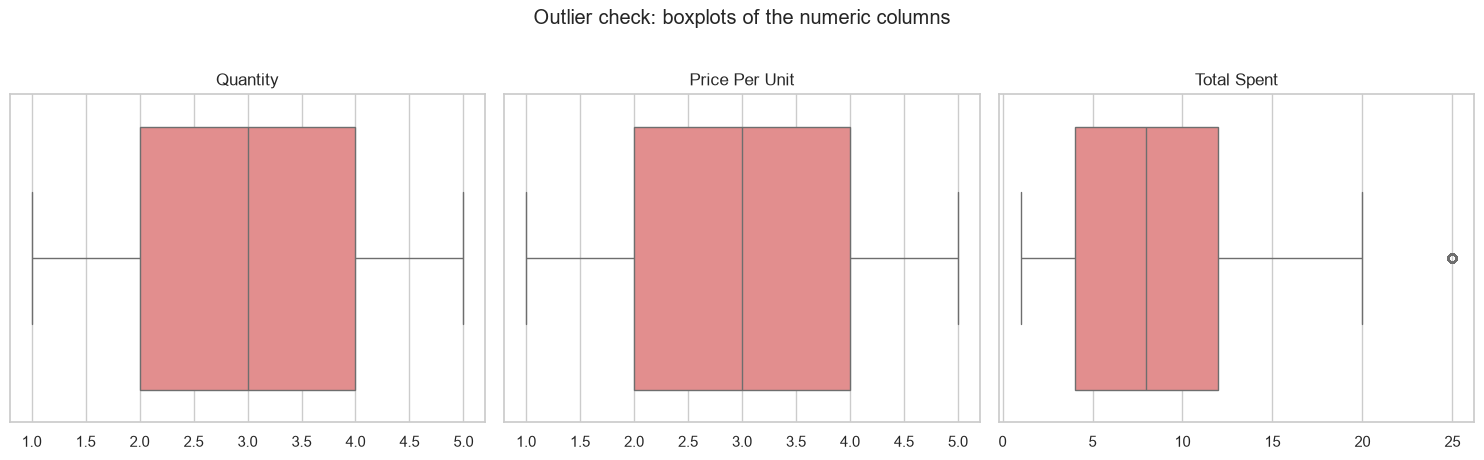

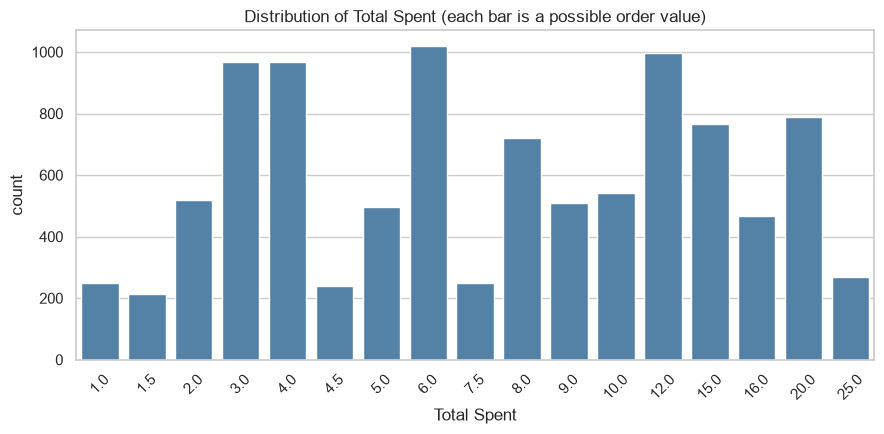

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, c in zip(ax, num_cols):
    sns.boxplot(x=df_clean[c].astype(float), ax=a, color="lightcoral")
    a.set_title(f"{c}")
    a.set_xlabel("")
plt.suptitle("Outlier check: boxplots of the numeric columns", y=1.02)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(x=df_clean["Total Spent"], color="steelblue", ax=ax)
ax.set_title("Distribution of Total Spent (each bar is a possible order value)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Outlier Detection

**Methods:** the IQR rule (a value is an outlier if it lies more than 1.5 x IQR below Q1 or above Q3) and the z-score rule (|z| > 3). Both were applied to every numeric column after the data types were corrected.

| Column | Min | Max | Mean | Q1 | Q3 | IQR fences | IQR outliers | Z-score outliers | Largest \|z\| |
|---|---|---|---|---|---|---|---|---|---|
| Quantity | 1 | 5 | 3.02 | 2 | 4 | -1 to 7 | 0 | 0 | 1.43 |
| Price Per Unit | 1.0 | 5.0 | 2.95 | 2.0 | 4.0 | -1 to 7 | 0 | 0 | 1.60 |
| Total Spent | 1.0 | 25.0 | 8.93 | 4.0 | 12.0 | -8 to 24 | **268** | 0 | 2.68 |

### Decision for each column

| Column | Finding | Decision | Justification |
|---|---|---|---|
| Quantity | No outliers by either method; values run from 1 to 5 | **Retain** | Every value is a valid order size, spread almost evenly across 1 to 5. |
| Price Per Unit | No outliers by either method | **Retain** | The six prices (1.0, 1.5, 2.0, 3.0, 4.0, 5.0) are the fixed menu prices of the 8 items. |
| Total Spent | 268 rows (2.7%) above the IQR upper fence of 24; none flagged by z-score | **Retain** | See below. |

### Why the 268 flagged orders were kept
- **They are valid orders, not errors.** All 268 are exactly 5 Salads at 5.0 each = **25.0**, which is the largest total the menu can produce (5 units x the most expensive price). All 17 distinct Total Spent values in the data are possible menu combinations.
- **The two methods disagree.** The highest value is only 2.68 standard deviations above the mean, so the z-score rule flags nothing. The IQR rule flags the top value because order totals take only 17 discrete values, and the fence (24) falls just below the maximum (25). With discrete, bounded values, a flag from the IQR rule alone is weak evidence of an error.
- **Removing them would lose information.** It would delete 2.7% of sales, all of the highest-value orders, and understate Salad revenue.
- **Capping would create an impossible value.** None of the 17 possible totals equals 24, so capping at the fence would produce orders that cannot exist and break the rule Total Spent = Quantity x Price Per Unit, which holds in 100% of rows.

### Range and plausibility checks
- Quantity is between 1 and 5 in every row, and Price Per Unit and Total Spent are positive in every row.
- All dates fall between 1 January and 31 December 2023, and none are in the future.
- The boxplots show a single flagged point for Total Spent (the value 25) and none for Quantity or Price Per Unit. The bar chart shows 17 possible order values, with 25.0 simply the last.

In [35]:
errors_after = placeholders - {"unknown"}

def count_placeholders(d, ph):
    total = 0
    for c in d.columns:
        if pd.api.types.is_numeric_dtype(d[c]) or pd.api.types.is_datetime64_any_dtype(d[c]):
            continue
        s = d[c].dropna().astype(str).str.strip().str.lower()
        total += int(s.isin(ph).sum())
    return total

def unknown_labels(d):
    return int(sum((d[c].astype(str) == "Unknown").sum() for c in ["Item", "Payment Method", "Location"]))

after = {
    "Rows": len(df_clean),
    "Columns": df_clean.shape[1],
    "Null cells": int(df_clean.isna().sum().sum()),
    "Columns containing nulls": int((df_clean.isna().sum() > 0).sum()),
    "ERROR / UNKNOWN placeholder strings": count_placeholders(df_clean, errors_after),
    "Cells labelled 'Unknown' (deliberate)": unknown_labels(df_clean),
    "Duplicate rows": int(df_clean.duplicated().sum()),
    "Columns with the correct dtype": f"{int(dtype_table['After correct?'].sum())} of 8",
    "Rows with a missing or 'Unknown' value": int((df_clean.isna() | (df_clean.astype(str) == "Unknown")).any(axis=1).sum()),
}

before_s = {
    "Rows": len(df_raw),
    "Columns": df_raw.shape[1],
    "Null cells": int(df_raw.isna().sum().sum()),
    "Columns containing nulls": int((df_raw.isna().sum() > 0).sum()),
    "ERROR / UNKNOWN placeholder strings": count_placeholders(df_raw, placeholders),
    "Cells labelled 'Unknown' (deliberate)": 0,
    "Duplicate rows": int(df_raw.duplicated().sum()),
    "Columns with the correct dtype": f"{int(dtype_table['Before correct?'].sum())} of 8",
    "Rows with a missing or 'Unknown' value": int((df_raw.isna() | df_raw.astype(str).apply(lambda s: s.str.strip().str.lower().isin(placeholders))).any(axis=1).sum()),
}

summary = pd.DataFrame({"Before cleaning": before_s, "After cleaning": after})
summary["Change"] = [
    (a - b if isinstance(a, int) and isinstance(b, int) else "") for b, a in zip(before_s.values(), after.values())
]
summary

,Before cleaning,After cleaning,Change
Rows,10000,9974,-26
Columns,8,8,0
Null cells,6826,460,-6366
Columns containing nulls,7,1,-6
ERROR / UNKNOWN placeholder strings,3256,0,-3256
Cells labelled 'Unknown' (deliberate),0,7594,7594
Duplicate rows,0,0,0
Columns with the correct dtype,4 of 8,8 of 8,
Rows with a missing or 'Unknown' value,6911,6203,-708


## 7. Before vs. After Cleaning

| Metric | Before cleaning | After cleaning | Change |
|---|---|---|---|
| Rows | 10,000 | 9,974 | -26 |
| Columns | 8 | 8 | 0 |
| Null cells | 6,826 | 460 | -6,366 |
| Columns containing nulls | 7 | 1 | -6 |
| ERROR / UNKNOWN placeholder strings | 3,256 | 0 | -3,256 |
| Cells labelled "Unknown" (deliberate) | 0 | 7,594 | +7,594 |
| Duplicate rows | 0 | 0 | 0 |
| Columns with the correct data type | 4 of 8 | 8 of 8 | +4 |
| Rows with a missing or "Unknown" value | 6,911 | 6,203 | -708 |
| Missing or "Unknown" cells (all columns) | 10,082 | 8,054 | -2,028 |

### Reading the table
- **Nulls fell from 6,826 to 460**, and the only column that still has nulls is Transaction Date. This is a deliberate choice, explained in section 2.
- **The null count understates the original problem.** Before cleaning, pandas counted 6,826 nulls, but a further 3,256 cells held the text `ERROR` or `UNKNOWN`, so the true number of missing cells was 10,082.
- **"Unknown" rose from 0 to 7,594 on purpose.** These cells (Item 474, Payment Method 3,168, Location 3,952) are values that could not be recovered, now labelled consistently and counted as a category instead of being hidden as missing or invented.
- **Missing or "Unknown" cells fell by 20%** (10,082 to 8,054). 2,028 values were either recovered exactly or removed with the 26 deleted rows.
- **The dataset is analysis-ready, not complete.** 6,203 rows (62.2%) still contain at least one missing or "Unknown" value, mainly in Payment Method (31.8% Unknown) and Location (39.6% Unknown). Analyses by those columns must report "Unknown" as its own group.
- **All 4 incorrect data types were fixed** (Quantity, Price Per Unit, Total Spent and Transaction Date), and no duplicates were ever present.

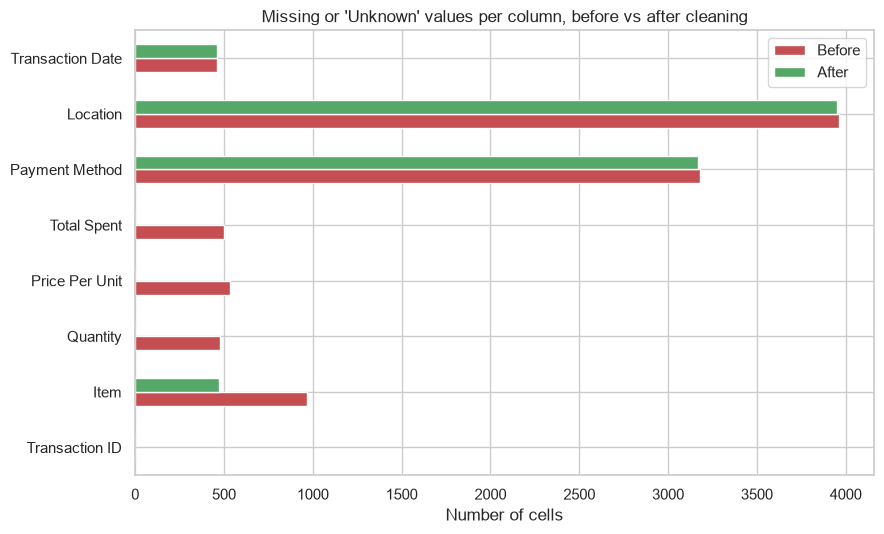

                  Before  After
Transaction ID         0      0
Item                 969    474
Quantity             479      0
Price Per Unit       533      0
Total Spent          502      0
Payment Method      3178   3168
Location            3961   3952
Transaction Date     460    460 
Total: 10082 -> 8054


In [36]:
miss_before = after_placeholders
miss_after = df_clean.isna().sum() + pd.Series({c: int((df_clean[c].astype(str) == "Unknown").sum()) for c in ["Item", "Payment Method", "Location"]}).reindex(df_clean.columns).fillna(0).astype(int)

cmp = pd.DataFrame({"Before": miss_before, "After": miss_after})
cmp.plot(kind="barh", figsize=(9, 5.5), color=["#c44e52", "#55a868"])
plt.title("Missing or 'Unknown' values per column, before vs after cleaning")
plt.xlabel("Number of cells")
plt.tight_layout()
plt.show()
print(cmp, "\nTotal:", int(cmp["Before"].sum()), "->", int(cmp["After"].sum()))

## 8. Saved Output

The cleaned dataset was saved to `output/cleaned_cafe_sales.csv` (9,974 rows, 8 columns), together with `output/before_after_summary.csv`.

- **Reload check:** reading the file back returns the same shape (9,974 x 8), the same 460 missing values (all in Transaction Date, stored as empty cells) and 0 duplicates.
- Dates are saved as YYYY-MM-DD, and "Unknown" is saved as the text `Unknown`.
- When loading it again, parse the date column with `parse_dates=["Transaction Date"]`.

In [37]:
df_clean.to_csv("output/cleaned_cafe_sales.csv", index=False, date_format="%Y-%m-%d")
summary.to_csv("output/before_after_summary.csv")

check = pd.read_csv("output/cleaned_cafe_sales.csv", parse_dates=["Transaction Date"])
print("Saved shape:", check.shape, "| matches:", check.shape == df_clean.shape)
print("Nulls after reload:", int(check.isna().sum().sum()), "| expected:", int(df_clean.isna().sum().sum()))
print("Duplicates after reload:", int(check.duplicated().sum()))
check.head()

Saved shape: (9974, 8) | matches: True
Nulls after reload: 460 | expected: 460
Duplicates after reload: 0


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,4.0,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,Unknown,Unknown,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


## 9. Cleaning Decision Log and Conclusion

| # | Step | What was found | Decision | Result |
|---|---|---|---|---|
| 1 | Placeholders | 3,256 cells held `ERROR` or `UNKNOWN`, invisible to `isna()` | Convert to proper missing values | True missing cells rose from 6,826 to 10,082 |
| 2 | Data types | Every column loaded as text; 4 of 8 wrong | Convert Quantity to integer, Price Per Unit and Total Spent to float, Transaction Date to datetime, text columns to category | 8 of 8 correct, no new nulls created |
| 3 | Recoverable numbers | Total = Quantity x Price in 100% of 8,544 complete rows; each item has one fixed price | Recompute missing Quantity, Price and Total; recover Item from price where unique | 1,462 of 1,514 missing numeric values recovered exactly; 489 items recovered |
| 4 | Unrecoverable numbers | 26 rows missing two numeric fields in an unresolvable combination | Delete these rows | 26 rows removed (0.26%) |
| 5 | Item | 480 left unresolved (price 3.0 or 4.0 fits two items) | Label "Unknown" | 474 labelled (6 were in deleted rows) |
| 6 | Payment Method, Location | 31.8% and 39.6% missing, no predictor, categories evenly split | Label "Unknown" instead of guessing | 3,168 and 3,952 labelled |
| 7 | Transaction Date | 460 missing; rows are not in date order | Keep as missing | No dates invented |
| 8 | Duplicates | None found, before or after recovery | Nothing to remove | 0 removed |
| 9 | Standardisation | No case or spacing variants; one date format; IDs follow one pattern | Strip spaces; one "Unknown" label | Consistent text columns |
| 10 | Outliers | 268 IQR flags in Total Spent, none by z-score | Retain: valid maximum orders (5 Salads at 5.0) | No values changed |

### Conclusion
Starting from 10,000 rows with 10,082 effectively missing cells, every missing numeric value that could be derived was recovered exactly from rules verified in the data, and only 26 rows (0.26%) were removed. Nothing was filled with a mean, median or mode where that would have invented information, and every decision is documented above.

### Limitations
- **Recovery depends on a verified but unproven assumption** that menu prices are fixed and Total = Quantity x Price. It held in 100% of complete rows, but it cannot be tested on the rows that were recovered.
- **62.2% of rows still contain at least one missing or "Unknown" value.** Payment Method (31.8%) and Location (39.6%) are not usable for reliable segmentation without stating the large "Unknown" group.
- **460 transactions have no date**, so they are excluded from any time analysis.
- **480 item values** could not be resolved when the price was 3.0 (Cake or Juice) or 4.0 (Smoothie or Sandwich). Item-level sales are slightly understated for those four products.
- **The dataset was built to be dirty.** It has no duplicates, no formatting variants and no real outliers, so those checks are documented as clean, not demonstrated.

In [39]:
%%writefile README.md
# Task 3 · Cleaning Data

**Track:** Data Analytics · **Level:** 1 · **Internship:** OIBSIP

## Objective
Take a deliberately messy dataset and turn it into a clean, analysis-ready one, documenting every decision: data quality report, missing-data strategy, duplicate removal, standardisation, outlier detection, data type correction, a before-versus-after summary and a saved cleaned file.

## Tech Stack
Python, pandas, numpy, matplotlib, seaborn, Jupyter Notebook

## Dataset
"Cafe Sales - Dirty Data for Cleaning Training" (Kaggle): 10,000 transactions, 8 columns (Transaction ID, Item, Quantity, Price Per Unit, Total Spent, Payment Method, Location, Transaction Date).

The raw file is not included in this repository. Download it from Kaggle (search the title above) and place `dirty_cafe_sales.csv` in the `data/` folder.

## Project Structure
```
DataAnalytics-L1-DataCleaning/
├── Task3_Data_Cleaning.ipynb
├── README.md
├── requirements.txt
├── data/            (place the raw CSV here)
├── output/          (cleaned dataset and summary table)
└── screenshots/     (key tables and charts)
```

## How to Run
```bash
pip install -r requirements.txt
jupyter notebook Task3_Data_Cleaning.ipynb
```
Then run all cells from top to bottom (Kernel → Restart & Run All). The cleaned file is written to `output/cleaned_cafe_sales.csv`.

## What the Notebook Covers
- [x] Data quality report: nulls per column, hidden placeholders, duplicates, data type problems, value ranges
- [x] Missing-data strategy chosen and justified for every column
- [x] Duplicate detection and removal (with the count documented)
- [x] Standardisation of text, placeholders and dates
- [x] Outlier detection with the IQR and z-score methods, with a decision per column
- [x] Data type correction for every column
- [x] Before-versus-after summary table
- [x] Cleaned dataset saved to CSV and checked by reloading it

## Data Quality Findings (before cleaning)
- **10,082 of 80,000 cells (12.6%) were effectively missing.** pandas counted only 6,826 nulls; another 3,256 cells held the text `ERROR` or `UNKNOWN`, which `isna()` does not detect.
- **69.1% of rows (6,911) had at least one gap**, so deleting incomplete rows would have destroyed most of the data.
- Payment Method (31.8%) and Location (39.6%) were the worst columns.
- **Every column loaded as text:** only 4 of 8 had an acceptable type. Quantity, Price Per Unit, Total Spent and Transaction Date were stored as text.
- **No duplicates** (0 rows, 0 repeated IDs) and **no case or spacing inconsistencies** were present.

## Cleaning Approach
| Step | Decision |
|---|---|
| Placeholders | `ERROR` and `UNKNOWN` converted to proper missing values |
| Quantity, Price Per Unit, Total Spent | **Recovered exactly, not estimated.** Total = Quantity x Price held in 100% of the 8,544 complete rows, and each item has one fixed menu price |
| Item | Recovered from the price where the price identifies one item (1.0, 1.5, 2.0, 5.0); labelled "Unknown" where it fits two (3.0 and 4.0) |
| Payment Method, Location | Labelled "Unknown": nothing predicts them, categories are evenly split, and mode imputation would invent thousands of values |
| Transaction Date | Left missing: rows are not in date order, so forward fill would be invalid |
| Unrecoverable rows | 26 rows (0.26%) missing two numeric fields in an unresolvable combination were deleted |
| Duplicates | None found, before or after recovery |
| Outliers | 268 Total Spent values flagged by the IQR rule were **retained**: all are 5 Salads at 5.0 = 25.0, the largest total the menu allows; the z-score method flags nothing, and capping would create an impossible value |

## Results

| Metric | Before | After |
|---|---|---|
| Rows | 10,000 | 9,974 |
| Null cells | 6,826 | 460 |
| Columns containing nulls | 7 | 1 |
| ERROR / UNKNOWN placeholder strings | 3,256 | 0 |
| Cells labelled "Unknown" (deliberate) | 0 | 7,594 |
| Duplicate rows | 0 | 0 |
| Columns with the correct data type | 4 of 8 | 8 of 8 |
| Missing or "Unknown" cells | 10,082 | 8,054 |

- **1,462 of 1,514 missing numeric values (96.6%) were recovered exactly.**
- The dataset is **analysis-ready, not complete**: 62.2% of rows still contain at least one missing or "Unknown" value, mostly in Payment Method and Location, so analyses by those columns must treat "Unknown" as its own group.

## Output
- `output/cleaned_cafe_sales.csv`: cleaned dataset, 9,974 rows and 8 columns
- `output/before_after_summary.csv`: the before-versus-after table

Load the cleaned file with `pd.read_csv("output/cleaned_cafe_sales.csv", parse_dates=["Transaction Date"])`.

## Limitations
- The recovery relies on a pattern verified in the complete rows (fixed menu prices, Total = Quantity x Price); it cannot be tested on the recovered rows themselves.
- 460 transactions have no date and 480 item values could not be resolved when the price was 3.0 or 4.0.
- The dataset is synthetic and built to be dirty: it has no duplicates, no formatting variants and no real outliers, so those checks are documented as clean, not demonstrated.

## Screenshots

### Missing values by column (before cleaning)
![Missing values report](screenshots/missing_values_report.png)

### Data types before and after
![Data types](screenshots/dtype_before_after.png)

### Outlier check: boxplots
![Outlier boxplots](screenshots/outlier_boxplots.png)

### Distribution of Total Spent
![Total Spent distribution](screenshots/total_spent_distribution.png)

### Before versus after summary
![Before after summary](screenshots/before_after_summary.png)

### Missing or "Unknown" values per column
![Missing values before and after](screenshots/missing_values_before_after.png)

Writing README.md


In [40]:
%%writefile requirements.txt
pandas>=2.0
numpy
matplotlib
seaborn
jupyter

Writing requirements.txt


In [41]:
import os
print(os.getcwd())
print(sorted(os.listdir(".")))

C:\Users\N6N0C\OIBSIP\DataAnalytics-L1-DataCleaning
['.ipynb_checkpoints', 'README.md', 'Task3_Data_Cleaning.ipynb', 'anaconda_projects', 'data', 'output', 'requirements.txt', 'screenshots']
